In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_MidBanesworLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,38.484687,%,2025-11-25 14:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,14:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,38.079250,%,2025-11-25 15:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,15:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,39.269903,%,2025-11-25 16:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,16:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,41.151625,%,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,17:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,40.904667,%,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,18:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,49.200500,%,2026-01-06 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,06:45:00
996,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,48.929639,%,2026-01-06 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,07:45:00
997,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,48.216875,%,2026-01-06 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,08:45:00
998,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,47.025000,%,2026-01-06 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,09:45:00


In [3]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [4]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-11-25,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,42.13,10
1,2025-11-26,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,43.60,24
2,2025-11-27,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,44.12,24
3,2025-11-28,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,43.68,24
4,2025-11-29,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,42.78,24
5,2025-11-30,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,44.43,24
6,2025-12-01,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,47.30,23
7,2025-12-02,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,48.80,24
8,2025-12-03,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,48.13,24
9,2025-12-04,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,44.52,24


/tmp/ipykernel_47520/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


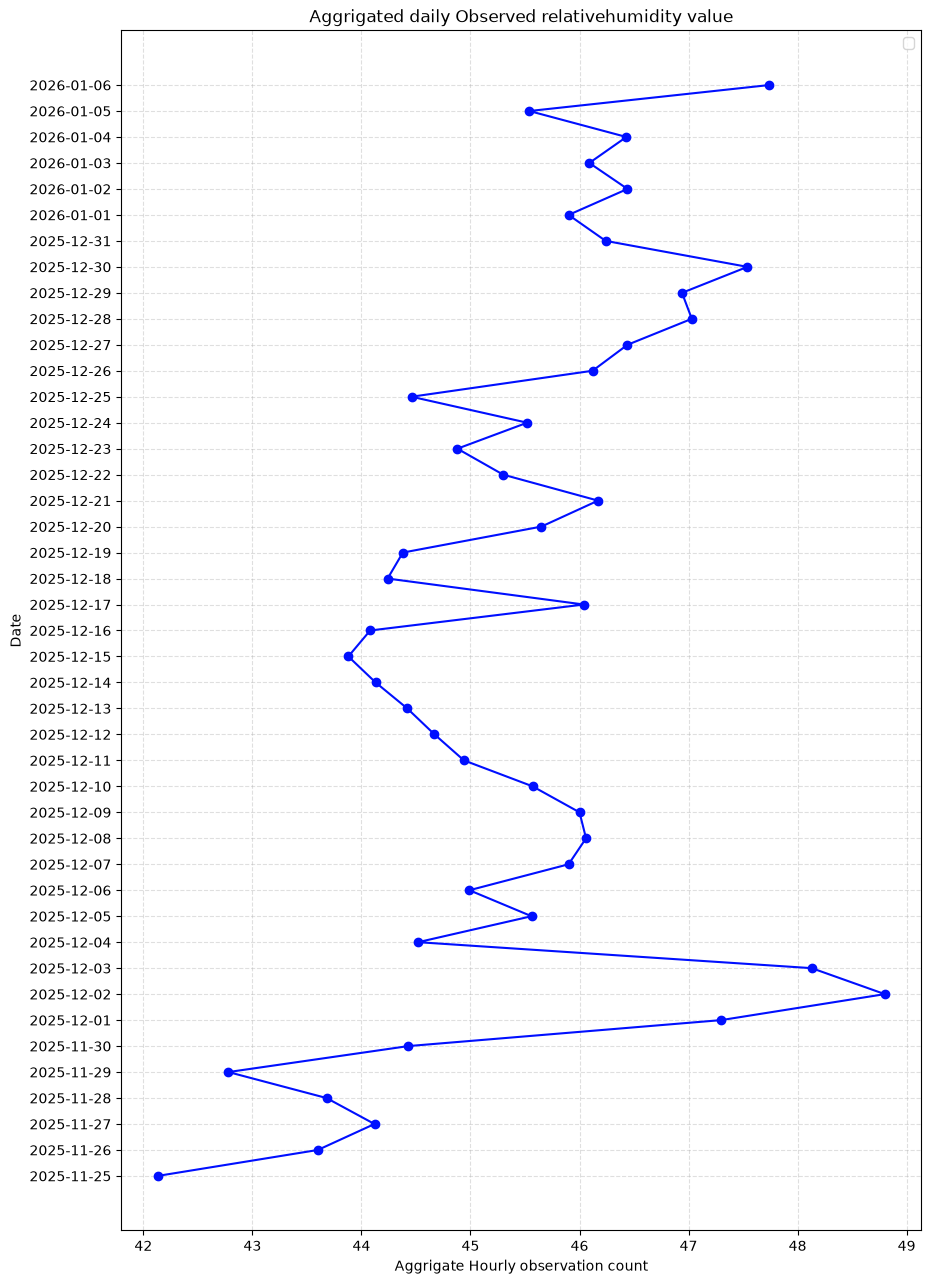

In [5]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and visualization of last 30 days

In [6]:
df30 = pd.read_csv('cleaned_MidBanesworLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,56.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,55.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,52.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,50.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,47.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,51.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
716,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,53.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
717,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,53.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
718,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,53.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [7]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [8]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,49.67,18
1,2026-09-13,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,50.08,24
2,2026-09-14,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,51.08,24
3,2026-09-15,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,50.71,24
4,2026-09-16,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,51.33,24
5,2026-09-17,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,49.62,24
6,2026-09-18,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,50.54,24
7,2026-09-19,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,49.88,24
8,2026-09-20,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,50.17,24
9,2026-09-21,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,%,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,50.12,24


/tmp/ipykernel_47520/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


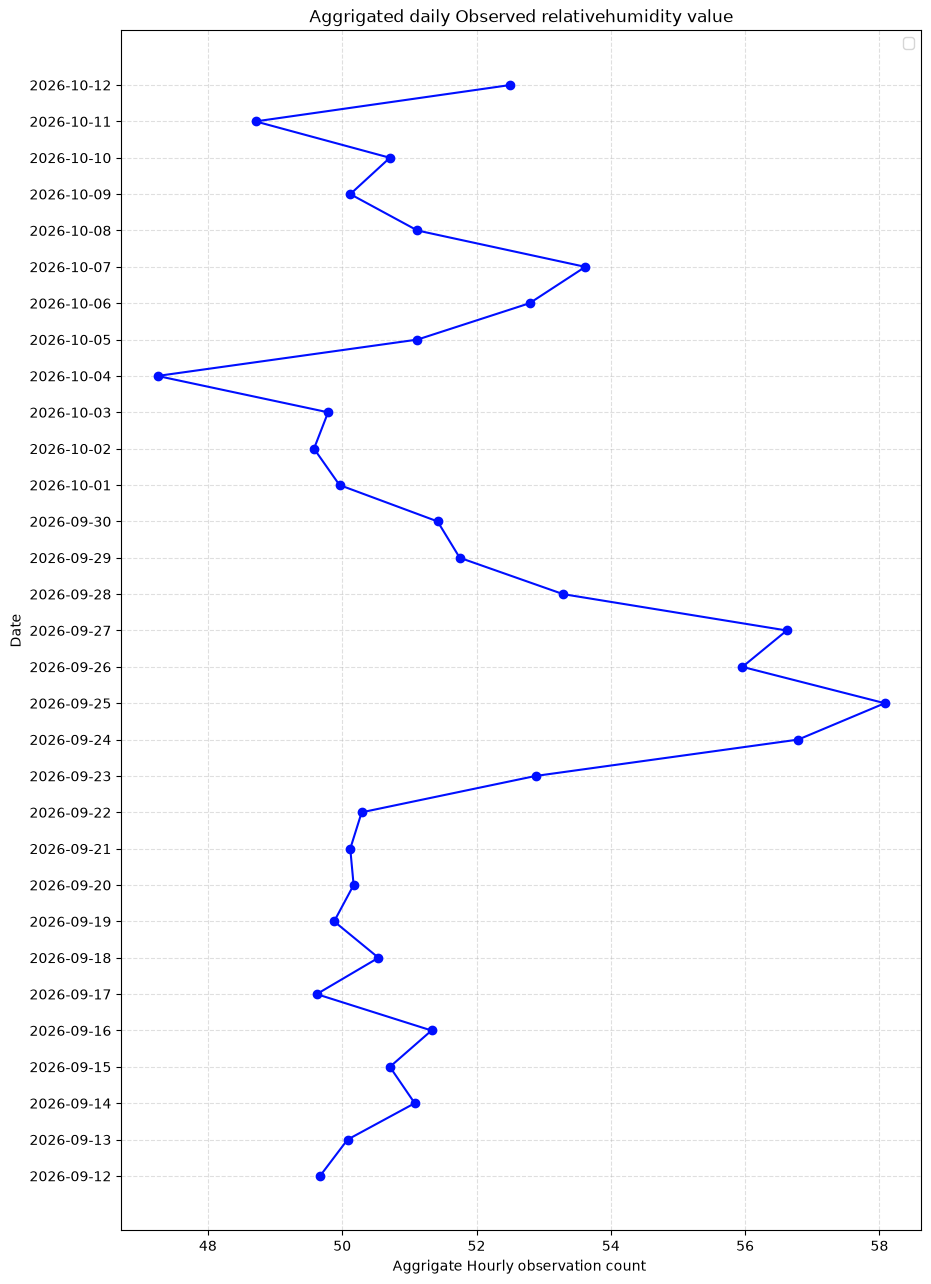

In [9]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [10]:
df7 = pd.read_csv('cleaned_MidBanesworLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,24.9,c,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,25.2,c,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.0,c,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.5,c,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.6,c,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.4,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.9,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.8,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [11]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [12]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,26.46,18
1,2026-10-06,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,25.34,24
2,2026-10-07,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,23.89,24
3,2026-10-08,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,24.13,24
4,2026-10-09,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,24.55,24
5,2026-10-10,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,23.32,24
6,2026-10-11,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,24.53,24
7,2026-10-12,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,c,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,23.03,6


/tmp/ipykernel_47520/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


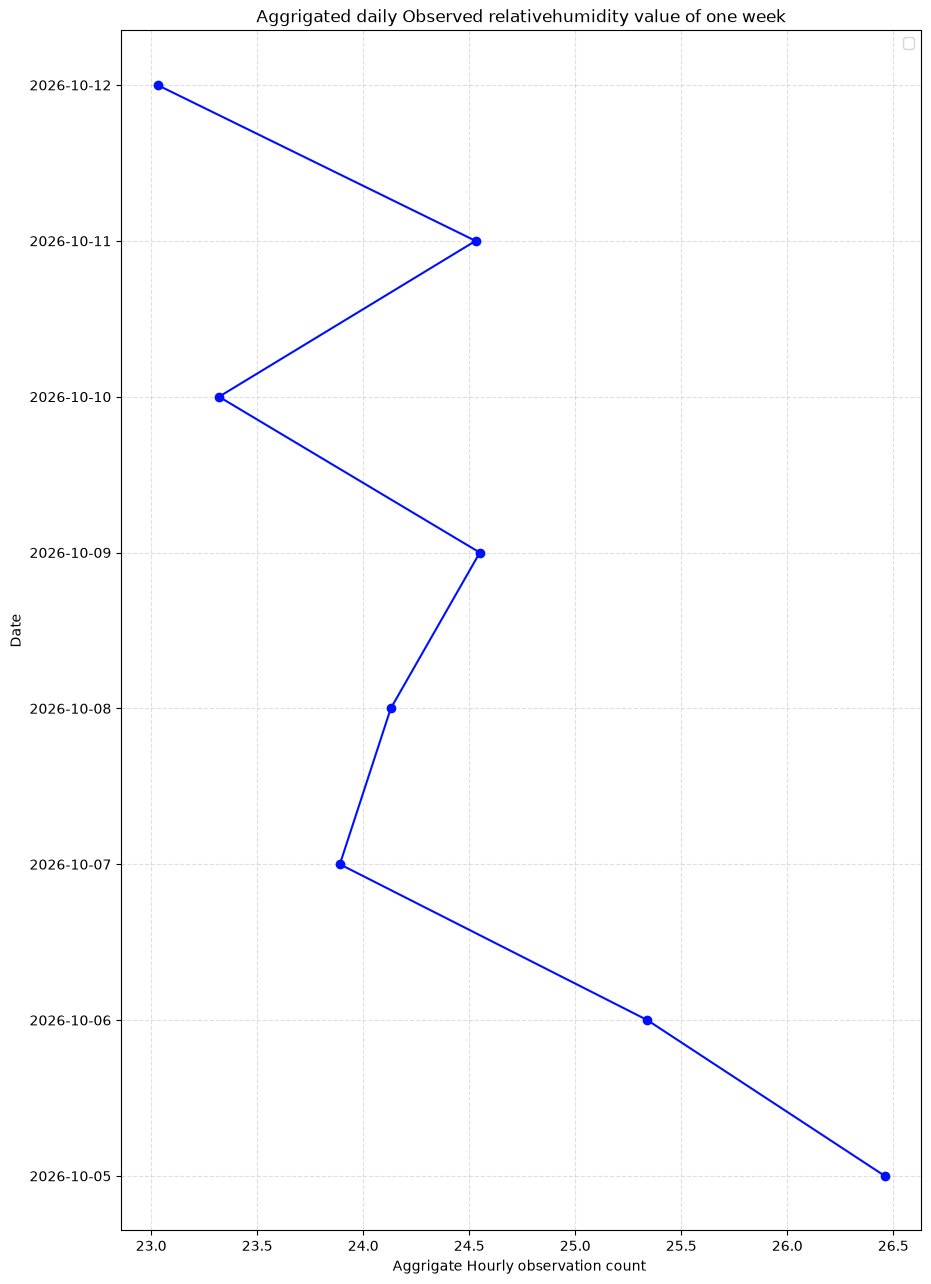

In [13]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [14]:
df24 = pd.read_csv('cleaned_MidBanesworLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,55.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,54.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,51.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,49.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,46.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,43.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,42.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,41.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,41.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6142022,Mid Baneshwor (SC-39)-GD Labs,relativehumidity,42.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


/tmp/ipykernel_47520/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


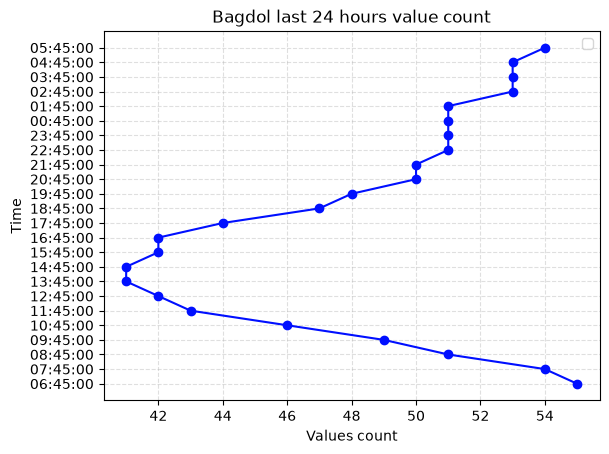

In [15]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()